[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HernanBustamanteG/lapis26-p3-corrientes/blob/main/notebooks/02_hito2_potenciales.ipynb)

# 02 · Hito 2: cuatro potenciales validados

**Qué pide el enunciado.** Los cuatro modelos validados y un gráfico de $|\mathbf a_{\rm MW}(t)|$ y de la
distancia de la LMC en función del tiempo.

**Las dos piezas que hay que validar.**
1. *El campo uniforme* $-\mathbf a_{\rm MW}(t)$ (modelos B y D). `gala` no tiene un potencial de campo uniforme:
   se imita con una masa puntual de Kepler a $d = 10^6$ kpc en la dirección $-\hat{\mathbf a}_{\rm MW}(t)$, con
   $m(t) = |\mathbf a_{\rm MW}(t)|\,d^2/G$ (`TimeInterpolatedPotential` con `origin` y `m` dependientes del tiempo).
   Su aceleración en la región de las corrientes debe ser $-\mathbf a_{\rm MW}$, con errores del orden de $r/d$.
2. *El modelo D completo.* Una partícula de prueba integrada en el modelo D (marco de la MW) tiene que seguir
   la misma trayectoria que la misma partícula integrada en el marco inercial, con la MW y la LMC moviéndose,
   cuando se resta la posición del centro de la MW.

In [1]:
# Celda 1: entorno. En Colab clona el repositorio, instala versiones fijas y monta Google Drive (las salidas
# quedan en MyDrive/lapis26_p3/salidas). Si numpy cambia de version, la sesion se reinicia UNA vez:
# vuelve a ejecutar esta celda. En una maquina propia solo comprueba versiones.
import os, sys, subprocess
REPO_URL = "https://github.com/HernanBustamanteG/lapis26-p3-corrientes.git"
USAR_DRIVE = True
if "google.colab" in sys.modules:
    RAIZ = "/content/lapis26-p3-corrientes"
    if not os.path.isdir(RAIZ):
        subprocess.run(["git", "clone", "-q", REPO_URL, RAIZ], check=True)
else:
    RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ)
os.chdir(RAIZ)
from p3streams import entorno
if entorno.en_colab():
    entorno.preparar_colab(RAIZ, montar_drive=USAR_DRIVE)
entorno.resumen();

Python 3.13.16
  numpy       2.2.6
  scipy       1.18.1
  astropy     8.0.2
  gala        1.12.0
  matplotlib  3.11.2


  pandas      3.1.0


  healpy      1.20.1
  galstreams  1.2.1
Salidas en: salidas
ffmpeg: /usr/bin/ffmpeg | CPU: 2
Entorno OK


In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
import matplotlib.pyplot as plt
from p3streams import config as C, util as U, estilo as E
E.usar()
SAL = U.carpeta_nueva("02_hito2")          # carpeta nueva de este notebook (nada se pisa)
FUENTE = "notebooks/02_hito2.ipynb, p3streams " + C.VERSION + ", " + U.ahora()
print("Salidas de este notebook:", SAL)

Salidas de este notebook: salidas/02_hito2_20261027_203736


In [3]:
import time
from p3streams import potenciales as P, figuras as F
sis = P.integrar_sistema()
print("Cobertura de los potenciales interpolados para t_start = 5 Gyr:", P.cobertura(sis, -5000.0))
t0 = time.time()
err = P.validar_campo(sis)
print("Campo uniforme: error relativo maximo %.1e entre 10 y 200 kpc (%.0f s)" % (err, time.time() - t0))

Cobertura de los potenciales interpolados para t_start = 5 Gyr: True


Campo uniforme: error relativo maximo 4.2e-04 entre 10 y 200 kpc (0 s)


In [4]:
t0 = time.time()
VAL = P.validar_inercial(sis)      # particula de prueba, orbita polar a 50 kpc, 4 Gyr: modelo D vs marco inercial
dx, tt, rd, ri = VAL
print("Modelo D vs marco inercial: |dx| maximo = %.2f pc en 4 Gyr (%.0f s)" % (dx * 1e3, time.time() - t0))

Modelo D vs marco inercial: |dx| maximo = 0.48 pc en 4 Gyr (134 s)


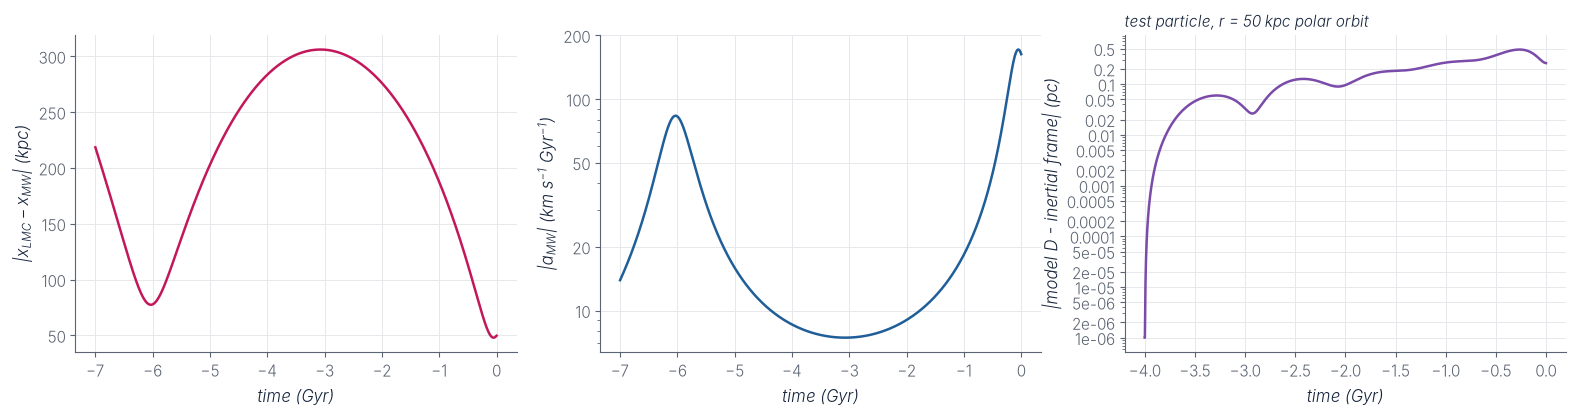

Figura: hito2_aMW_dLMC_validacion.png 
Milestone 2. Left: distance between the LMC and the MW centre from the two-body integration with dynamical friction (MW and LMC models of the LAPIS26 tutorial). Centre: magnitude of the acceleration of the MW centre caused by the LMC, |a_MW(t)|; models B and D add the uniform field -a_MW(t). Right: difference between a test particle integrated in model D (MW frame) and the same particle integrated in the inertial frame, after subtracting the MW centre.


In [5]:
fig = F.hito2(sis, val=(tt, rd, ri))
PIE = 'Milestone 2. Left: distance between the LMC and the MW centre from the two-body integration with dynamical friction (MW and LMC models of the LAPIS26 tutorial). Centre: magnitude of the acceleration of the MW centre caused by the LMC, |a_MW(t)|; models B and D add the uniform field -a_MW(t). Right: difference between a test particle integrated in model D (MW frame) and the same particle integrated in the inertial frame, after subtracting the MW centre.'
E.guardar(fig, os.path.join(SAL, 'hito2_aMW_dLMC_validacion.png'), PIE, FUENTE, pdf=True)
plt.show()
print("Figura:", 'hito2_aMW_dLMC_validacion.png', "\n" + PIE)

**Ojo con la historia orbital de la LMC en este modelo.** Con la MW y la LMC del tutorial
($1.8\times10^{11}\,M_\odot$) y la fricción dinámica de van der Marel et al. (2012), la integración hacia atrás da
una LMC **ligada**, con un pericentro anterior hace ~6 Gyr (valores exactos abajo). Es una propiedad del modelo
(la masa de la MW y la fricción la determinan), no una conclusión sobre la LMC real: buena parte de la
literatura favorece una primera caída [conocimiento general, ver Vasiliev 2023]. Para las corrientes que empiezan
a formarse hace 4 a 5 Gyr, ese pericentro antiguo queda fuera; lo que las perturba es el pericentro actual.

In [6]:
a = np.linalg.norm(sis.a_mw(sis.t), axis=1) * 977.792221 * 1e3   # kpc/Myr^2 -> km/s/Gyr
i = np.argmax(a)
print("|a_MW| maximo = %.0f km/s/Gyr a t = %.0f Myr (LMC a %.1f kpc); hoy %.0f km/s/Gyr"
      % (a[i], sis.t[i], sis.d_lmc()[i], a[np.argmin(np.abs(sis.t))]))
print("Hace 2 Gyr: %.1f km/s/Gyr (LMC a %.0f kpc)" % (a[np.argmin(np.abs(sis.t + 2000))], sis.d_lmc()[np.argmin(np.abs(sis.t + 2000))]))
d = sis.d_lmc()
mins = np.where((d[1:-1] < d[:-2]) & (d[1:-1] <= d[2:]))[0] + 1
maxs = np.where((d[1:-1] > d[:-2]) & (d[1:-1] >= d[2:]))[0] + 1
for j in mins:
    print("Pericentro de la LMC: %.1f kpc a t = %.2f Gyr" % (d[j], sis.t[j] / 1e3))
for j in maxs:
    print("Apocentro de la LMC: %.0f kpc a t = %.2f Gyr" % (d[j], sis.t[j] / 1e3))
U.escribir_texto("Hito 2 (%s): campo uniforme error %.1e; D vs inercial %.2f pc; |a_MW| max %.0f km/s/Gyr a t = %.0f Myr."
                 % (U.ahora(), err, dx * 1e3, a[i], sis.t[i]), os.path.join(SAL, "registro.txt"))

|a_MW| maximo = 171 km/s/Gyr a t = -51 Myr (LMC a 47.9 kpc); hoy 163 km/s/Gyr
Hace 2 Gyr: 9.0 km/s/Gyr (LMC a 276 kpc)
Pericentro de la LMC: 77.4 kpc a t = -6.03 Gyr
Pericentro de la LMC: 47.9 kpc a t = -0.05 Gyr
Apocentro de la LMC: 306 kpc a t = -3.07 Gyr
